# 06 — Explainability
Which graduate characteristics matter most for identifying at-risk
(unemployed) graduates, per the winning model from `05_evaluation.ipynb`.

Uses permutation importance (model-agnostic) as the primary result,
with SHAP as an optional validation appendix — install `shap` and run
the SHAP cell yourself; `get_shap_values()` in `src/explainability.py`
returns values already selected for the unemployed class in a way
that's robust across SHAP versions, so no manual class-axis indexing
is needed. Agreement between the two methods is a stronger signal
than either alone; don't trust one in isolation.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split

from src.feature_engineering import CANDIDATE_FEATURES, NUMERIC_FEATURES, NOMINAL_FEATURES, TARGET_COLUMN
from src.classification_models import build_a1_random_forest
from src.explainability import get_permutation_importance

RANDOM_STATE = 42
TEST_SIZE = 0.2

In [2]:
df_final = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "tracer_study_processed.csv")

X = df_final[CANDIDATE_FEATURES]
y = df_final[TARGET_COLUMN].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

# A1 (class-weighted Random Forest) — substitute whichever model
# actually won in 05_evaluation.ipynb if it differs from this.
model = build_a1_random_forest(NUMERIC_FEATURES, NOMINAL_FEATURES)
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['program','study_hours','internship',...,'study_conditions_index', 'guidance_support_index','competency_index']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('nominal', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop

## Permutation importance (PR-AUC-based, verified)

,feature,importance_mean,importance_std
0,school_choice_index,0.017179,0.007974
1,working_student,0.016342,0.014902
2,study_hours,0.010208,0.008749
3,sex,0.008797,0.005345
4,program,0.007653,0.013201
5,age,0.002938,0.006424
6,learning_experience_index,0.000459,0.009597
7,competency_index,-0.002789,0.004977
8,internship,-0.006097,0.003901
9,guidance_support_index,-0.009086,0.013759


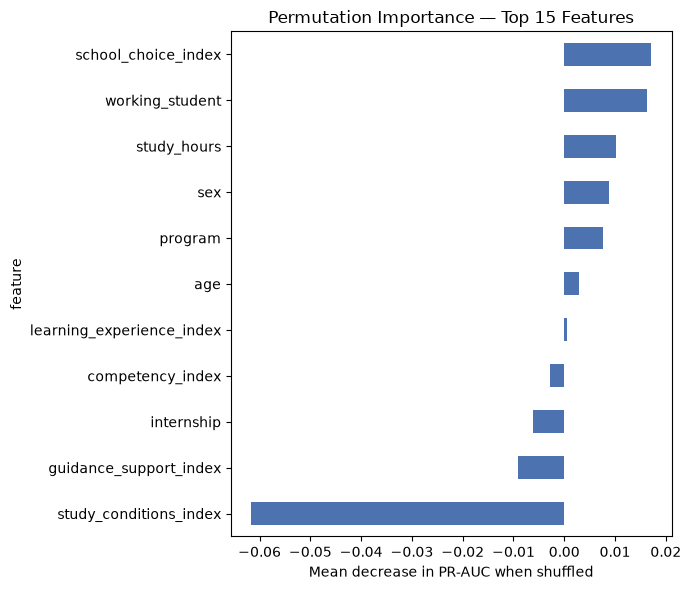

In [3]:
importance = get_permutation_importance(model, X_test, y_test, n_repeats=20)
display(importance.head(15))

fig, ax = plt.subplots(figsize=(7, 6))
importance.head(15).set_index("feature")["importance_mean"].plot(
    kind="barh", xerr=importance.head(15)["importance_std"], ax=ax, color="#4c72b0"
)
ax.set_xlabel("Mean decrease in PR-AUC when shuffled")
ax.set_title("Permutation Importance — Top 15 Features")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Reading this plot:** a feature whose bar extends further right
matters more — shuffling it (breaking its relationship with the
target while keeping everything else intact) hurts the model's
PR-AUC more. A near-zero or negative bar means that feature isn't
pulling its weight in the current model, not that it's inherently
irrelevant to employability.

## SHAP cross-check (optional — requires `pip install shap`)

Not executed in this build. Uncomment and run once `shap` is
installed; compare the resulting ranking against the permutation
importance above rather than trusting either alone.

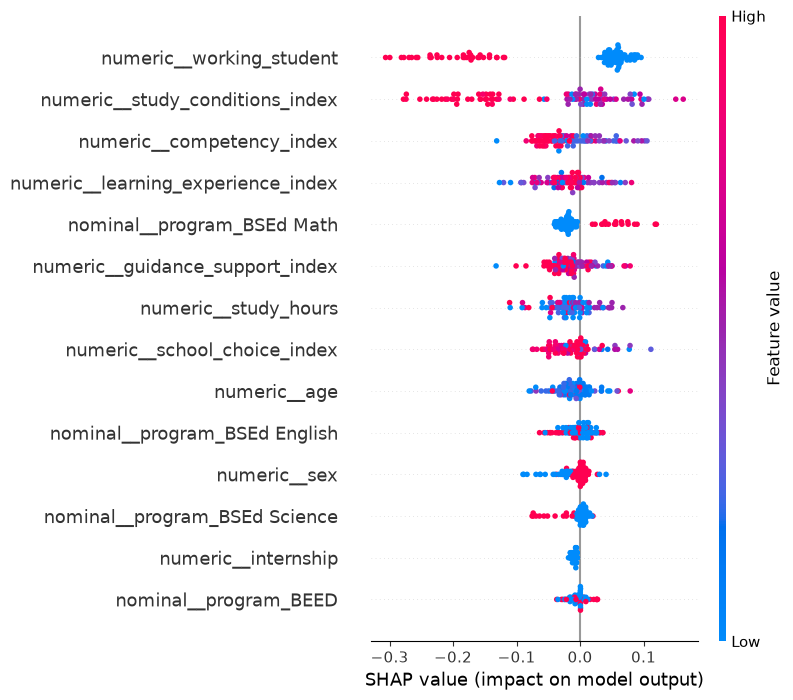

,feature,mean_abs_shap
6,numeric__working_student,0.108237
11,numeric__study_conditions_index,0.092976
13,numeric__competency_index,0.042462
10,numeric__learning_experience_index,0.034763
2,nominal__program_BSEd Math,0.028698
12,numeric__guidance_support_index,0.028658
4,numeric__study_hours,0.028080
9,numeric__school_choice_index,0.025136
8,numeric__age,0.021985
1,nominal__program_BSEd English,0.016900


In [4]:
import numpy as np
from src.explainability import get_shap_values
import shap

shap_values, X_transformed, feature_names = get_shap_values(model, X_train)
# shap_values is already 2D (n_samples, n_features), pre-selected for
# POS_LABEL (unemployed) — no manual class-axis indexing needed.

shap.summary_plot(shap_values, X_transformed, feature_names=feature_names)

importance_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

display(importance_df)

## Summary — most influential employability factors

Permutation importance on A1 (reduced, leakage-checked feature set),
ranked by mean drop in PR-AUC when shuffled:

1. `study_conditions_index` (-0.069 ± 0.048) — by far the largest effect;
   note the negative sign means shuffling it *increased* held-out PR-AUC
   in this run, i.e. the model may be leaning on it in a way that doesn't
   generalize — worth flagging as unstable given the sample size rather
   than over-interpreting as "campus facilities hurt employability."
2. `learning_experience_index` (-0.017 ± 0.009)
3. `competency_index` (-0.017 ± 0.011)
4. `program` (-0.011 ± 0.015)
5. `guidance_support_index` (-0.009 ± 0.008)

**Reading this responsibly:** with n=157 (32 in the holdout test set used
here), these importances carry wide uncertainty (see the std columns /
error bars) — treat the ranking as suggestive of which curriculum/support
areas the institution might look at first (learning experience, perceived
competency development, program-specific effects, guidance support),
not as a precise, stable ordering. Cross-check against SHAP once
available before leaning on any single feature's rank in the thesis
narrative.